In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema
# import zarr
%matplotlib inline
import torch
from torch import nn
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
%matplotlib inline
from matplotlib.font_manager import FontProperties

In [ ]:
all_data = pd.read_csv('/HH_data_0-3000.csv')
all_data

,Vehicle_ID,timestamp,x_lead,x_follow,v_lead,v_follow,a_lead,a_follow,distance,delta_v,smooth_v_follow,smooth_distance,smooth_delta_v,FrameID,time_headway
0,3,0.000000,0.000000,-21.618937,15.205611,15.397437,-0.125165,0.056585,16.618937,-0.191827,15.397437,16.618937,-0.191827,0,1.079331
1,3,0.099981,1.491581,-19.663385,15.198118,15.402246,-0.098205,0.101276,16.154966,-0.204129,15.398499,16.516541,-0.194542,1,1.072607
2,3,0.199914,2.995142,-18.280299,15.168826,15.379181,-0.056524,0.165915,16.275442,-0.210355,15.394235,16.463331,-0.198032,2,1.069448
3,3,0.299796,4.532177,-16.775873,15.174463,15.399492,-0.007223,0.237887,16.308050,-0.225029,15.395396,16.429061,-0.203990,3,1.067141
4,3,0.399628,6.001878,-15.287254,15.136314,15.446208,0.039555,0.301572,16.289132,-0.309894,15.406610,16.398180,-0.227362,4,1.064360
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269911,3269,19.498973,253.028891,221.216828,13.721215,15.462352,0.387660,-0.119246,26.812063,-1.741137,15.498167,27.348703,-1.881125,195,1.764641
269912,3269,19.599125,254.462814,222.731108,13.765573,15.457951,0.416530,-0.167302,26.731706,-1.692378,15.489292,27.212535,-1.839469,196,1.756861
269913,3269,19.699221,255.793112,224.253326,13.776517,15.444704,0.450095,-0.192211,26.539786,-1.668187,15.479451,27.064062,-1.801668,197,1.748386
269914,3269,19.799358,257.092018,225.791360,13.797768,15.436351,0.484257,-0.202276,26.300658,-1.638583,15.469939,26.895582,-1.765676,198,1.738571


In [ ]:
class Segmentation():
    def __init__(self,all_data,desired_vehicle_id):
        self.all_data = all_data
        self.unique_vehicle_ids = all_data['Vehicle_ID'].unique()
        self.desired_vehicle_id = desired_vehicle_id

    def cal_inflection_points(self,data):
        local_minima = argrelextrema(data, np.less)
        local_maxima = argrelextrema(data, np.greater)
        inflection_points = np.sort(np.concatenate((local_minima[0], local_maxima[0])))
        inflection_indexs = [i for i in inflection_points]
        inflection_indexs.insert(0,0)
        inflection_indexs.append(len(data)-1)
        inflection_coordinates = [data[i] for i in inflection_indexs]
        delta_x = np.diff(inflection_indexs)
        delta_y = np.diff(inflection_coordinates)
        delta_x = np.append(delta_x, 0)
        delta_y = np.append(delta_y, 0)

        return inflection_indexs, inflection_coordinates,delta_x,delta_y

    def generate_result_dataset(self,variables): #variables: Velocity_x, Acceleration_x, distance, delta_v
        results = []
        for vehicle_id in self.unique_vehicle_ids:
            vehicle_data = all_data[all_data['Vehicle_ID'] == vehicle_id]
            time_id = vehicle_data['FrameID'].values
            speed = vehicle_data[str(variables)].values
            inflection_points, inflection_coordinates, delta_x, delta_y = self.cal_inflection_points(speed)
            inflection_time_ids = [time_id[i] for i in inflection_points]
            result_data = pd.DataFrame({
                'VehicleID': vehicle_id,
                'InflectionTimeID': inflection_time_ids,
                'InflectionSpeed': inflection_coordinates,
                'DeltaX': delta_x,
                'DeltaY': delta_y
            })
            results.append(result_data)
        result_dataset = pd.concat(results, ignore_index=True)
        return result_dataset

    def find_data(self,result_dataset):
        single_vehicle_result = result_dataset[result_dataset['VehicleID'] == self.desired_vehicle_id]
        single_vehicle_data = all_data[all_data['Vehicle_ID'] == self.desired_vehicle_id]
        delta_t = single_vehicle_result['DeltaX'].values
        delta_y = single_vehicle_result['DeltaY'].values
        time_turning_points = single_vehicle_result['InflectionTimeID'].values
        turning_points_values = single_vehicle_result['InflectionSpeed'].values
        return single_vehicle_data,delta_t,delta_y,time_turning_points,turning_points_values

    def get_states_set(self,delta_y,theta1,theta2):
        states = []
        # try 1 st
        for dy in delta_y:
            if dy >= theta1:
                state = 'I'
            elif dy <= theta2:
                state = 'D'
            else:
                state = 'K'
            states.append(state)
        return states

    def merge(self,states,delta_t,delta_y,time_turning_points,theta1,theta2,gama):
        merged_index_set = []
        for index, j in enumerate(states):
            if index < 1:
                if states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
            elif index == len(states)-1:
                if states[index-1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
            else:
                if states[index-1] != j and states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
                elif states[index-1] == j and states[index+1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index-1]
                        merged_index_set.append(index)
                elif states[index+1] == j and states[index-1] != j:
                    if delta_t[index] <= gama and theta2 <= delta_y[index] <= theta1:
                        states[index] = states[index+1]
                        merged_index_set.append(index)
        try:
            merged_index_set.remove(0)
        except:
            pass
        try:
            merged_index_set.remove(len(time_turning_points)-1)
        except:
            pass
        time_turning_points_final = np.delete(time_turning_points, merged_index_set)

        return time_turning_points_final,merged_index_set

    def cal_states_final(self,states,variable,turning_point,merged_index_set):
        if str(variable) == 'a_follow':
            variable_threshold = 0.25 # 0.2
        elif str(variable) == 'smooth_v_follow':
            variable_threshold = 13
        elif str(variable) == 'time_headway':
            variable_threshold = 1.5  # distance, 10, 12
        elif str(variable) == 'smooth_delta_v':
            variable_threshold = 0.8
        else:
            variable_threshold = np.inf
        for index, point in enumerate(turning_point):
            if states[index] == 'K':
                if index != turning_point.shape[0]-1:
                    next_point = turning_point[index]
                else:
                    next_point = turning_point[-1]
                point -= turning_point[0]
                next_point -= turning_point[0]
                mean_variable = np.mean(single_vehicle_data[str(variable)][point:next_point+1])
                if mean_variable >= variable_threshold or mean_variable <= -variable_threshold:
                    states[index] = 'H'
                else:
                    states[index] = 'L'
        states_final = [i for index,i in enumerate(states) if index not in merged_index_set]
        return states_final

    def total_turning_points(self,v_turning_points,a_turning_points,d_turning_points,dv_turning_points,gamma):
        total_ = np.concatenate((v_turning_points,a_turning_points,d_turning_points,dv_turning_points))
        total_ = np.unique(total_)
        total_points = []
        real_points = []
        for i, num in enumerate(total_):
            if i == 0:
                total_points.append(num)
            else:
                v_close = self.find_nearest_smaller(v_turning_points,num)
                a_close = self.find_nearest_smaller(a_turning_points,num)
                d_close = self.find_nearest_smaller(d_turning_points,num)
                dv_close = self.find_nearest_smaller(dv_turning_points,num)
                if (num-total_points[-1]) >=gamma:
                    if (num-v_close)>=gamma and (num-a_close)>=gamma and (num-d_close)>=gamma and (num-dv_close)>=gamma:
                        total_points.append(total_[i-1])
                        total_points.append(num)
                        real_points.append(total_[i-1])
        if total_[-1] not in total_points:
            total_points.append(total_[-1])
            real_points.append(total_[-1])
        total_points = sorted(set(total_points))
        real_points = sorted(set(real_points))
        return total_points,real_points

    def total_turning_points_without_gamma(self,v_turning_points,a_turning_points,d_turning_points,dv_turning_points):
        total_ = np.concatenate((v_turning_points,a_turning_points,d_turning_points,dv_turning_points))
        total_ = np.unique(total_)
        # total_points = sorted(set(total_))
        return total_

    def find_nearest_smaller(self,array, value):
        array = np.array(array)
        smaller_values = array[array < value]
        if smaller_values.size == 0:
            return value
        nearest_index = np.abs(smaller_values - value).argmin()
        return smaller_values[nearest_index]

    def find_nearest_smaller2(self,array, value):
        array = np.array(array)
        smaller_values = array[array <= value]
        if smaller_values.size == 0:
            return None
        nearest_index = np.abs(smaller_values - value).argmin()
        return smaller_values[nearest_index]

    def four_variable_point_state(self,four_variable_turning_points,time_turning_points,states_final):
        four_state = list(states_final)
        four_point = list(time_turning_points)
        for i, total_point in reversed(list(enumerate(four_variable_turning_points))):
            for j, base_point in enumerate(time_turning_points):
                if j != time_turning_points.shape[0]-1:
                    if total_point > base_point and total_point < time_turning_points[j+1]:
                        four_point.insert(j+1,total_point)
                        four_state.insert(j+1,states_final[j])
                    break
        return four_point,four_state

    def merge_adj_same_states(self,final_points,final_states):
        del_index_set = []
        for index, point in enumerate(final_points):
            if index != 0 and index != len(final_points)-1:
                if final_states[index] == final_states[index-1]:
                    del_index_set.append(index)
        final_points = [item for index, item in enumerate(final_points) if index not in del_index_set]
        final_states = [item for index, item in enumerate(final_states) if index not in del_index_set]
        return final_points,final_states

    def find_four_states(self,four_df):
        four_states =[]
        v_final_point4 = four_df['velocity_turning_points']
        v_final_states4 = four_df['velocity_states']
        a_final_point4 = four_df['acceleration_turning_points']
        a_final_states4 = four_df['acceleration_states']
        d_final_point4 = four_df['distance_turning_points']
        d_final_states4 = four_df['distance_states']
        dv_final_point4 = four_df['delta_v_turning_points']
        dv_final_states4 = four_df['delta_v_states']
        four_variable_turning_points = four_df['four_turning_points']
        four_real_points = four_df['four_real_points']
        for i in four_real_points:
            v_loc = v_final_point4.index(self.find_nearest_smaller2(v_final_point4,i))
            a_loc = a_final_point4.index(self.find_nearest_smaller2(a_final_point4,i))
            d_loc = d_final_point4.index(self.find_nearest_smaller2(d_final_point4,i))
            dv_loc = dv_final_point4.index(self.find_nearest_smaller2(dv_final_point4,i))
            four_states.append([v_final_states4[v_loc],a_final_states4[a_loc],d_final_states4[d_loc],dv_final_states4[dv_loc]])
        return four_states


    def all_states(self,four_variable_turning_points_wo_gama,final_point4,final_states4):
        states = []
        for i, value_i in enumerate(four_variable_turning_points_wo_gama):
            for j,value_j in enumerate(final_point4):
                if j != len(final_point4)-1:
                # print(value_i,final_point4,'wqwqwqwqw')
                    if value_i == value_j:
                        states.append(final_states4[j])
                    elif value_i > value_j and value_i < final_point4[j+1]:
                        states.append(final_states4[j])
                    else:
                        continue
                else:
                    states.append(final_states4[j])
                    break
        return states

    def binary_states(self,four_variable_turning_points_wo_gama,v_all_state4,a_all_state4,d_all_state4,dv_all_state4,gamma):
        binary_state = []
        binary_state1 = []
        binary_state2 = []
        for i, value in enumerate(four_variable_turning_points_wo_gama):
            if i != len(four_variable_turning_points_wo_gama)-1:

                if four_variable_turning_points_wo_gama[i+1]-value <gamma:
                    binary_state.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i],'short'))
                    binary_state1.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                    binary_state2.append('short')
                else:
                    binary_state.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i],'long'))
                    binary_state1.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                    binary_state2.append('long')

        return binary_state,binary_state1,binary_state2

    def binary_states_del_too_short(self,four_variable_turning_points_wo_gama,v_all_state4,a_all_state4,d_all_state4,dv_all_state4,gamma):
        binary_state_not_short = []
        binary_state1_not_short = []
        binary_state2_not_short = []
        too_short = 10
        four_variable_turning_points_wo_gama_del_too_short = []
        for i, value in enumerate(four_variable_turning_points_wo_gama):
            if i != len(four_variable_turning_points_wo_gama)-1:

                if four_variable_turning_points_wo_gama[i+1]-value < gamma:
                    if four_variable_turning_points_wo_gama[i+1]-value >= too_short:
                        binary_state_not_short.append(((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]),'st'))
                        binary_state1_not_short.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                        binary_state2_not_short.append('st')
                        four_variable_turning_points_wo_gama_del_too_short.append(value)
                else:
                    binary_state_not_short.append(((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]),'lg'))
                    binary_state1_not_short.append((v_all_state4[i],a_all_state4[i],d_all_state4[i],dv_all_state4[i]))
                    binary_state2_not_short.append('lg')
                    four_variable_turning_points_wo_gama_del_too_short.append(value)
        return four_variable_turning_points_wo_gama_del_too_short,binary_state_not_short,binary_state1_not_short,binary_state2_not_short


    def choose_action_phase(self, single_four_points, single_vehicle_data,binary_state1):
        action_phase = []
        too_short = 10
        four_variable_action_point = []
        labels = []
        for i, value in enumerate(single_four_points):
            if i != len(single_four_points)-1:
                if single_four_points[i+1]-value >= too_short:
                    index = np.where(single_vehicle_data['FrameID'].values == value)[0][0]
                    index_next = np.where(single_vehicle_data['FrameID'].values == single_four_points[i+1])[0][0]
                    if index_next-index >= too_short:
                        action_phase.append((single_vehicle_data['smooth_v_follow'].values[index: index_next+1],single_vehicle_data['a_follow'].values[index: index_next+1],single_vehicle_data['time_headway'].values[index: index_next+1],single_vehicle_data['smooth_delta_v'].values[index: index_next+1]))
                        four_variable_action_point.append(value)
                        labels.append(binary_state1[i])
        return four_variable_action_point, action_phase,labels

    def plt_segment(self,variable,y_label,single_vehicle_data,state_final,turning_point,time_turning_points_og):
        # create a plot for the segmentation of a single vehicle's data
        plt.figure(figsize=(10, 5))
        x_min = min(single_vehicle_data['FrameID'])
        x_max = max(single_vehicle_data['FrameID'])
        plt.xlim(x_min, x_max)
        plt.plot(single_vehicle_data['FrameID'].values, single_vehicle_data[str(variable)].values, color = 'red', linestyle='-', linewidth=1)

        plt.xlabel('Time')
        plt.ylabel(str(y_label))
        plt.title('Segmentation')

        # add vertical lines for turning points
        for i, state in enumerate(time_turning_points_og):
            start = time_turning_points_og[i]
            if start == time_turning_points_og[-1]:
                end = time_turning_points_og[i]
            else:
                end = time_turning_points_og[i+1]
            x_pos = (start + end) / 2
            plt.axvline(x=start, color='grey', linestyle='--', alpha=0.5)
        plt.axvline(x=time_turning_points_og[-1], color='grey', linestyle='--', alpha=0.5)
        plt.axvline(x=0, color='grey', linestyle='--', alpha=0.5)

        # fill the areas between turning points with colors based on state_final
        for i in range(len(state_final)):
            start = turning_point[i]
            if i != len(state_final)-1:
                end = turning_point[i + 1]
            else:
                end = int(single_vehicle_data['FrameID'].values[-1])

            color = None
            if state_final[i] == 'I':
                color = 'red'
            elif state_final[i] == 'H':
                color = 'yellow'
            elif state_final[i] == 'L':
                color = 'green'
            elif state_final[i] == 'D':
                color = 'blue'
            plt.axvspan(start, end, color=color, alpha=0.4,lw=0)
        plt.show()
        return

    def fill_color(self,velocity, acceleration, distance, delta_v, dataframe,axvspan,four_variable_turning_points,single_vehicle_data):
        COLOR_SET = [['#AED6F1', '#85C1E9', '#5DADE2', '#3498DB'],['#A9DFBF', '#82E0AA', '#58D68D', '#2ECC71'],['#F5B7B1', '#F1948A', '#EC7063', '#E74C3C'],['#D7BDE2', '#C39BD3', '#AF7AC5', '#9B59B6']]
        loc= [3.5,2.5,1.5,.5]

        fig,ax = plt.subplots(1,1,figsize=(20,1.5))
        plt.ylim(0,4)
        ax.yaxis.set_major_locator(plt.MultipleLocator(1))
        velocity_turning_points_final = dataframe['velocity_turning_points']
        velocity_states_final = dataframe['velocity_states']
        acceleration_turning_points_final =  dataframe['acceleration_turning_points']
        acceleration_states_final = dataframe['acceleration_states']
        distance_turning_points_final =  dataframe['distance_turning_points']
        distance_states_final = dataframe['distance_states']
        delta_v_turning_points_final =  dataframe['delta_v_turning_points']
        delta_v_states_final = dataframe['delta_v_states']
        if velocity:
            color_set = COLOR_SET[0]
            location = loc[0]
            for i in range(len(velocity_states_final)):
                if velocity_states_final[i] == 'I':
                    color = color_set[0]
                elif velocity_states_final[i] == 'H':
                    color = color_set[1]
                elif velocity_states_final[i] == 'L':
                    color = color_set[2]
                elif velocity_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(velocity_states_final)-1:
                    ax.fill_between([velocity_turning_points_final[i],velocity_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['smooth_v_follow'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        if acceleration:
            color_set = COLOR_SET[1]
            location = loc[1]
            for i in range(len(acceleration_states_final)):
                if acceleration_states_final[i] == 'I':
                    color = color_set[0]
                elif acceleration_states_final[i] == 'H':
                    color = color_set[1]
                elif acceleration_states_final[i] == 'L':
                    color = color_set[2]
                elif acceleration_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(acceleration_states_final)-1:
                    # print(color,'a')
                    ax.fill_between([acceleration_turning_points_final[i],acceleration_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['a_follow'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        if distance:
            color_set = COLOR_SET[2]
            location = loc[2]
            for i in range(len(distance_states_final)):
                if distance_states_final[i] == 'I':
                    color = color_set[0]
                elif distance_states_final[i] == 'H':
                    color = color_set[1]
                elif distance_states_final[i] == 'L':
                    color = color_set[2]
                elif distance_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(distance_states_final)-1:
                    # print(color,'d')
                    ax.fill_between([distance_turning_points_final[i],distance_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['time_headway'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        if delta_v:
            color_set = COLOR_SET[3]
            location = loc[3]
            for i in range(len(delta_v_states_final)):
                if delta_v_states_final[i] == 'I':
                    color = color_set[0]
                elif delta_v_states_final[i] == 'H':
                    color = color_set[1]
                elif delta_v_states_final[i] == 'L':
                    color = color_set[2]
                elif delta_v_states_final[i] == 'D':
                    color = color_set[3]
                else:
                    color=[]
                if i < len(delta_v_states_final)-1:
                    # print(color,'dv')
                    ax.fill_between([delta_v_turning_points_final[i],delta_v_turning_points_final[i+1]],location-0.5,location+0.5,color=color,alpha=0.8,linewidth=0)
            if axvspan != 0:
                for i in four_variable_turning_points:
                    plt.axvline(x=i, color='black', linestyle='-', alpha=1)
            if single_vehicle_data.size !=0:
                data = np.array(single_vehicle_data['smooth_delta_v'].values)
                normalized_data =  (data - np.min(data)) / (np.max(data) - np.min(data))
                plt.plot(single_vehicle_data['FrameID'].values, normalized_data+location-0.5, color = 'red', linestyle='-', linewidth=1)
        plt.rcParams['xtick.labelsize'] = 16
        plt.rcParams['ytick.labelsize'] = 16
        y_ticks_loc = [0.5,1.5,2.5,3.5]
        y_ticks = [r'$\Delta v$', r'$T$', r'$a$', r'$v$']
        ax.set_yticks(y_ticks_loc)
        ax.set_yticklabels(y_ticks)
        # ax.grid(None)
        font = {'family': 'Arial',
        'color': 'black',
        'weight': 'normal',
        'size': 18,
        }
        plt.xlim(velocity_turning_points_final[0],velocity_turning_points_final[-1])
        ax.set_xlabel('FrameID', fontdict=font)
        ax.set_ylabel('Variable', fontdict=font)
        # ax.set_title('Driving behavior map (Example of ID245)', fontsize=16)
        ax.grid(False)
        plt.show()
        return


In [ ]:
four_df = {}
df = {}
four_turning_points = {}
all_vehicle_df = {}
total_states = []
total_states1 = []
total_states2 = []
mse_results = []
df_action_phase = {}
action_phases_list = []
action_phases_labels_list = []
unique_vehicle_ids = all_data['Vehicle_ID'].unique()
for index, desired_vehicle_id in enumerate(unique_vehicle_ids):
    # desired_vehicle_id = 270
    print(index)
    sg = Segmentation(all_data, desired_vehicle_id)

    result_dataset_velocity = sg.generate_result_dataset('smooth_v_follow')
    result_dataset_acceleration = sg.generate_result_dataset('a_follow')
    result_dataset_distance = sg.generate_result_dataset('time_headway')
    result_dataset_delta_v = sg.generate_result_dataset('smooth_delta_v')

    theta1_velocity = 1.5  # 101
    theta2_velocity = -theta1_velocity
    theta1_acceleration = 0.25
    theta2_acceleration = -theta1_acceleration
    theta1_distance = 0.15
    theta2_distance = -theta1_distance
    theta1_delta_v = 0.8
    theta2_delta_v = -theta1_delta_v

    gama = 20
    single_vehicle_data, delta_t_v, delta_y_v, time_turning_points_v, turning_points_values_v = sg.find_data(result_dataset_velocity)
    _, delta_t_a, delta_y_a, time_turning_points_a, turning_points_values_a = sg.find_data(result_dataset_acceleration)
    _, delta_t_d, delta_y_d, time_turning_points_d, turning_points_values_d = sg.find_data(result_dataset_distance)
    _, delta_t_dv, delta_y_dv, time_turning_points_dv, turning_points_values_dv = sg.find_data(result_dataset_delta_v)

    states_v = sg.get_states_set(delta_y_v, theta1_velocity, theta2_velocity)
    states_a = sg.get_states_set(delta_y_a, theta1_acceleration, theta2_acceleration)
    states_d = sg.get_states_set(delta_y_d, theta1_distance, theta2_distance)
    states_dv = sg.get_states_set(delta_y_dv, theta1_delta_v, theta2_delta_v)

    turning_points_final_v, merged_index_set_v = sg.merge(states_v, delta_t_v, delta_y_v, time_turning_points_v,
                                                          theta1_velocity, theta2_velocity, gama)
    turning_points_final_a, merged_index_set_a = sg.merge(states_a, delta_t_a, delta_y_a, time_turning_points_a,
                                                          theta1_acceleration, theta2_acceleration, gama)
    turning_points_final_d, merged_index_set_d = sg.merge(states_d, delta_t_d, delta_y_d, time_turning_points_d,
                                                          theta1_distance, theta2_distance, gama)
    turning_points_final_dv, merged_index_set_dv = sg.merge(states_dv, delta_t_dv, delta_y_dv,
                                                            time_turning_points_dv, theta1_delta_v, theta2_delta_v,
                                                            gama)

    states_v_final = sg.cal_states_final(states_v, 'smooth_v_follow', time_turning_points_v, merged_index_set_v)
    states_a_final = sg.cal_states_final(states_a, 'a_follow', time_turning_points_a, merged_index_set_a)
    states_d_final = sg.cal_states_final(states_d, 'time_headway', time_turning_points_d, merged_index_set_d)
    states_dv_final = sg.cal_states_final(states_dv, 'smooth_delta_v', time_turning_points_dv, merged_index_set_dv)

    four_variable_turning_points, _ = sg.total_turning_points(turning_points_final_v, turning_points_final_a,
                                                              turning_points_final_d, turning_points_final_dv, gama)

    four_variable_turning_points_wo_gama = sg.total_turning_points_without_gamma(turning_points_final_v,
                                                                                 turning_points_final_a,
                                                                                 turning_points_final_d,
                                                                                 turning_points_final_dv)
    # print(four_variable_turning_points_wo_gama,'eeeeeeeeeeeee')
    v_final_point4, v_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,
                                                                   turning_points_final_v, states_v_final)
    a_final_point4, a_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,
                                                                   turning_points_final_a, states_a_final)
    d_final_point4, d_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,
                                                                   turning_points_final_d, states_d_final)
    dv_final_point4, dv_final_states4 = sg.four_variable_point_state(four_variable_turning_points_wo_gama,
                                                                     turning_points_final_dv, states_dv_final)
    # print(v_final_point4,v_final_states4,a_final_point4,a_final_states4 ,d_final_point4,d_final_states4 ,'eeeeeeeeeerrrrrrrrrrr')

    v_final_point4, v_final_states4 = sg.merge_adj_same_states(v_final_point4, v_final_states4)
    a_final_point4, a_final_states4 = sg.merge_adj_same_states(a_final_point4, a_final_states4)
    d_final_point4, d_final_states4 = sg.merge_adj_same_states(d_final_point4, d_final_states4)
    dv_final_point4, dv_final_states4 = sg.merge_adj_same_states(dv_final_point4, dv_final_states4)
    # four_variable_turning_points,four_real_points = sg.total_turning_points(v_final_point4,a_final_point4,d_final_point4,dv_final_point4,gama)
    four_variable_turning_points_wo_gama = sg.total_turning_points_without_gamma(v_final_point4, a_final_point4,
                                                                                 d_final_point4, dv_final_point4)
    four_real_points = four_variable_turning_points_wo_gama

    v_all_state4 = sg.all_states(four_variable_turning_points_wo_gama, v_final_point4, v_final_states4)
    a_all_state4 = sg.all_states(four_variable_turning_points_wo_gama, a_final_point4, a_final_states4)
    d_all_state4 = sg.all_states(four_variable_turning_points_wo_gama, d_final_point4, d_final_states4)
    dv_all_state4 = sg.all_states(four_variable_turning_points_wo_gama, dv_final_point4, dv_final_states4)

    # binary_state,binary_state1,binary_state2 = sg.binary_states(four_variable_turning_points_wo_gama,v_all_state4,a_all_state4,d_all_state4,dv_all_state4,gama)

    four_variable_turning_points_wo_gama, binary_state, binary_state1, binary_state2 = sg.binary_states_del_too_short(
        four_variable_turning_points_wo_gama, v_all_state4, a_all_state4, d_all_state4, dv_all_state4, gama)
    # print(binary_state,'llllooo')
    total_states.append(binary_state)
    total_states1.append(binary_state1)
    total_states2.append(binary_state2)

    # segment_points, action_phase_selection = sg.choose_action_phase(four_variable_turning_points_wo_gama, single_vehicle_data)
    segment_points, action_phase_selection, label_set_selection = sg.choose_action_phase(four_variable_turning_points_wo_gama, single_vehicle_data, binary_state1)

    four_df['velocity_turning_points'] = v_final_point4
    four_df['velocity_states'] = v_final_states4
    four_df['acceleration_turning_points'] = a_final_point4
    four_df['acceleration_states'] = a_final_states4
    four_df['distance_turning_points'] = d_final_point4
    four_df['distance_states'] = d_final_states4
    four_df['delta_v_turning_points'] = dv_final_point4
    four_df['delta_v_states'] = dv_final_states4
    four_df['four_turning_points'] = four_variable_turning_points
    four_df['four_real_points'] = four_real_points

    df['velocity_turning_points'] = turning_points_final_v
    df['velocity_states'] = states_v_final
    df['acceleration_turning_points'] = turning_points_final_a
    df['acceleration_states'] = states_a_final
    df['distance_turning_points'] = turning_points_final_d
    df['distance_states'] = states_d_final
    df['delta_v_turning_points'] = turning_points_final_dv
    df['delta_v_states'] = states_dv_final
    all_vehicle_df['{0}'.format(desired_vehicle_id)] = df
    df_action_phase['{0}'.format(desired_vehicle_id)] = [action_phase_selection, binary_state[: -1]]
    action_phases_list.append(action_phase_selection)
    action_phases_labels_list.append(label_set_selection)

    four_states = sg.find_four_states(four_df)

    sg.plt_segment('smooth_v_follow','Velocity',single_vehicle_data,states_v_final,turning_points_final_v,time_turning_points_v)
    sg.plt_segment('a_follow','Acceleration',single_vehicle_data,states_a_final,turning_points_final_a,time_turning_points_a)
    sg.plt_segment('time_headway','Distance',single_vehicle_data,states_d_final,turning_points_final_d,time_turning_points_d)
    sg.plt_segment('smooth_delta_v','Delta_v',single_vehicle_data,states_dv_final,turning_points_final_dv,time_turning_points_dv)
    #
    sg.fill_color(1,1,1,1,dataframe = df,axvspan=0,four_variable_turning_points=[],single_vehicle_data=np.empty((0,0)))

    sg.fill_color(1,1,1,1,four_df,1,four_variable_turning_points_wo_gama,single_vehicle_data)
    if index > 2:
        break

## Extract all action phases for drivers
action_phase_set = []
for i in action_phases_list:
    action_phases = [torch.from_numpy(np.stack(phase)) for phase in i]
    action_phase_set.append(action_phases)

# Create an empty list to store the extracted action phases
all_action_phases = []

# Iterate over the dataset
for driver_data in action_phase_set:
    # Iterate over the action phases for each driver
    for action_phase in driver_data:
        # Append the action phase to the list
        all_action_phases.append(action_phase)

## Extract all action labels for drivers
action_labels_set = []
for i in action_phases_list:
    action_labels = [torch.from_numpy(np.stack(phase)) for phase in i]
    action_labels_set.append(action_labels)

# Create an empty list to store the extracted action phases
all_action_labels = []

# Iterate over the dataset
for driver_data in action_phases_labels_list:
    # Iterate over the action phases for each driver
    for action_label in driver_data:
        # Append the action phase to the list
        all_action_labels.append(action_label)

np.save("all_action_phases.npy", all_action_phases)
np.save("all_action_labels.npy", all_action_labels)
np.save("total_states.npy", total_states)
np.save("mse_results.npy", mse_results)
np.save("action_phases_list.npy", action_phases_list)
np.save("action_phases_labels_list.npy", action_phases_labels_list)

The number of action phases: 18800

In [ ]:
## Extract original action phases
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import torch

velocity = []
acceleration =[]
distance = []
delta_v = []
velocity = np.concatenate([seg[0] for veh in action_phases_list for seg in veh],axis=0)
acceleration = np.concatenate([seg[1] for veh in action_phases_list for seg in veh],axis=0)
distance = np.concatenate([seg[2] for veh in action_phases_list for seg in veh],axis=0)
delta_v = np.concatenate([seg[3] for veh in action_phases_list for seg in veh],axis=0)

# Reshape the data to fit the scaler
velocity = velocity.reshape(-1, 1)
acceleration = acceleration.reshape(-1, 1)
distance = distance.reshape(-1, 1)
delta_v = delta_v.reshape(-1, 1)

# Use np.split to split the normalized arrays back into their original chunks
lengths = [len(seg[0]) for item in action_phases_list for seg in item]
velocity_chunks_v1 = np.split(velocity, np.cumsum(lengths)[:-1])
acceleration_chunks_v1 = np.split(acceleration, np.cumsum(lengths)[:-1])
distance_chunks_v1 = np.split(distance, np.cumsum(lengths)[:-1])
delta_v_chunks_v1 = np.split(delta_v, np.cumsum(lengths)[:-1])
# velocity_chunks
data_original = list(zip(velocity_chunks_v1, acceleration_chunks_v1, distance_chunks_v1, delta_v_chunks_v1))
action_phase_set_original = [tuple(torch.tensor(arr.reshape(-1)) for arr in tup) for tup in data_original]

np.save("action_phase_set_original.npy", action_phase_set_original)

In [28]:
# check action lables
data = action_phases_labels_list
# Flatten the list of lists to get a single list of tuples
flat_list = [tup for sublist in data for tup in sublist]
# Get unique tuples
unique_tuples = set(flat_list)
# Check the number of unique tuples
num_unique_tuples = len(unique_tuples)
print(num_unique_tuples)

255


Number of vehicles: 255

In [29]:
# Check lengths of action phases
lengths = [tensor.size(1) for tensor in all_action_phases]

# Compute min, max, and mean of lengths
min_length = min(lengths)
max_length = max(lengths)
mean_length = np.mean(lengths)

print(f"Min Length: {min_length}")
print(f"Max Length: {max_length}")
print(f"Mean Length: {mean_length}")

Min Length: 11
Max Length: 134
Mean Length: 24.823563829787233


Min Length: 11
Max Length: 134
Mean Length: 24.823563829787233

# Resample norm

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import torch.nn.functional as F
import torch

In [ ]:
## ''''Resample data to the same length
# Find the median, shorten resampling, longer truncating
def interpolate(phase, target_length):
    resampled_phase = signal.resample(phase, target_length)
    return resampled_phase

def downsample(phase, target_length):
    truncated_phase = phase[:target_length]
    return truncated_phase

# Action phases data (example)
action_phases = all_action_phases  # Contains all the action phases with four variables

# Resample the action phases for each variable
resampled_all_action_phases = []
for variable_idx in range(len(action_phases[0])):
    variable_data = [phase[variable_idx] for phase in action_phases]
    variable_lengths = [len(variable) for variable in variable_data]
    median_length = int(np.median(variable_lengths))

    resampled_variable_data = []
    for variable in variable_data:
        if len(variable) < median_length:
            resampled_variable = interpolate(variable, median_length)
            resampled_variable = torch.from_numpy(resampled_variable)
        elif len(variable) > median_length:
            resampled_variable = downsample(variable, median_length)
        else:
            resampled_variable = variable
        resampled_variable_data.append(resampled_variable)

    resampled_all_action_phases.append(resampled_variable_data)

# Convert resampled action phases to a numpy array
resampled_all_action_phases = np.array(resampled_all_action_phases)
resampled_all_action_phases = np.transpose(resampled_all_action_phases)

resampled_all_action_phases_tensor = []
for i in resampled_all_action_phases:
    resampled_all_action_phases_tensor.append([i[0].tolist(),i[1].tolist(),i[2].tolist(), i[3].tolist()])
resampled_all_action_phases_tensor = torch.tensor(resampled_all_action_phases_tensor)

len(resampled_all_action_phases_tensor)
np.save("resampled_all_action_phases.npy", resampled_all_action_phases_tensor)

In [ ]:
# Normalized data. 
# Reshape the data to fit the scaler
import numpy as np
from sklearn.preprocessing import MinMaxScaler

data = resampled_all_action_phases_tensor.reshape(resampled_all_action_phases_tensor.shape[0], resampled_all_action_phases_tensor.shape[1], -1)

# ####  Normalize each variable separately
scaler = MinMaxScaler()
normalized_data = np.empty_like(data)

for i in range(data.shape[2]):
    scaler.fit(data[:, :, i])
    normalized_data[:, :, i] = scaler.transform(data[:, :, i])

np.save("normalized_data.npy", normalized_data)

# PCA

In [37]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
normalized_data = np.load("normalized_data.npy")

0.9608186900615692


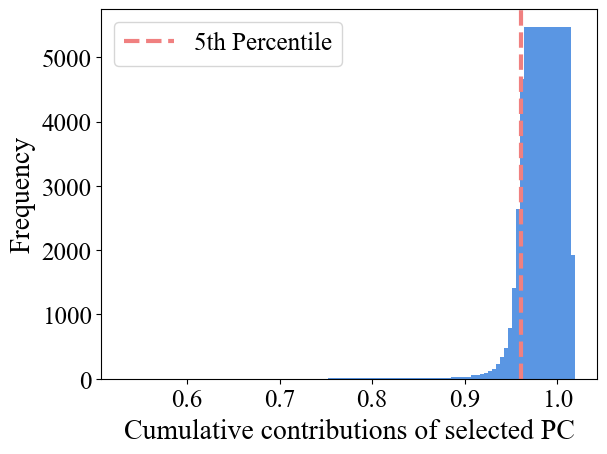

In [ ]:
data = normalized_data
explained_variance_ratios = []

for i in range(len(data)):
    action_phase = data[i]
    flattened_data = action_phase.reshape(4, -1)
    pca = PCA(n_components=1)  # set n_components to 1 for cumulative explained variance
    pca.fit(flattened_data)
    explained_variance_ratio = np.sum(pca.explained_variance_ratio_)
    explained_variance_ratios.append(explained_variance_ratio)

hist, bins = np.histogram(explained_variance_ratios, bins=100)  # adjust the number of bins as needed
# calculate the 5th percentile
percentile = np.percentile(explained_variance_ratios, 5)
print(percentile)
font = {'family': 'Times New Roman', 'weight': 'normal', 'size': 18}
plt.rc('font', **font)
plt.bar(bins[:-1], hist, width=0.05, color = '#5A96E3')  # adjust the width of the bars as needed
plt.xlabel('Cumulative contributions of selected PC', fontsize=20)
plt.ylabel('Frequency', fontsize=20)
# plt.title('Frequency Histogram of Cumulative Explained Variance Ratio', fontsize=16)
plt.tick_params(axis='both', which='major', labelsize=18) 
plt.grid(False) 

# add a vertical line at the 5th percentile
plt.axvline(percentile, color='lightcoral', linewidth=3, linestyle='--', label='5th Percentile')
plt.legend() 

plt.savefig('Cluster_PCA.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
data = normalized_data
action_phase_components = []
action_phase_component_scores = []

for i in range(len(data)):
    action_phase = data[i]
    flattened_data = action_phase.reshape(-1, 4)
    pca = PCA(n_components=1)
    principal_components = pca.fit_transform(flattened_data)
    action_phase_components.append(principal_components)
    component_scores = pca.components_.T
    action_phase_component_scores.append(component_scores)

np.save("action_phase_components.npy",action_phase_components)

In [42]:
all_action_labels

array([['H', 'D', 'L', 'I'],
       ['H', 'D', 'L', 'L'],
       ['H', 'D', 'L', 'L'],
       ...,
       ['H', 'L', 'I', 'H'],
       ['H', 'D', 'H', 'L'],
       ['H', 'L', 'I', 'H']], dtype='<U1')

# Clustering

In [43]:
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

action_phase_components = np.load("action_phase_components.npy")
all_action_phases = np.load("all_action_phases.npy", allow_pickle=True)
all_action_labels = np.load("all_action_labels.npy", allow_pickle=True)
resampled_all_action_phases = np.load("resampled_all_action_phases.npy", allow_pickle=True)

# Dictionary to convert labels into numbers
label_to_num = {'I': 0, 'D': 1, 'H': 2, 'L': 3}
# Convert labels to numbers
numeric_labels = [[label_to_num[l] for l in seq] for seq in all_action_labels]

# One-hot encode the numeric labels
label_onehot = []
for seq in numeric_labels:
    seq_onehot = np.eye(4, dtype=np.uint8)[seq]
    label_onehot.append(seq_onehot)

label_onehot = np.array(label_onehot)
reshaped_labels = label_onehot.reshape(label_onehot.shape[0], -1)

print(reshaped_labels)

# Clustering

Hierarchical clustering

Cluster 0: 0 samples
Cluster 1: 3301 samples
Cluster 2: 5544 samples
Cluster 3: 4124 samples
Cluster 4: 480 samples
Cluster 5: 1877 samples
Cluster 6: 3474 samples


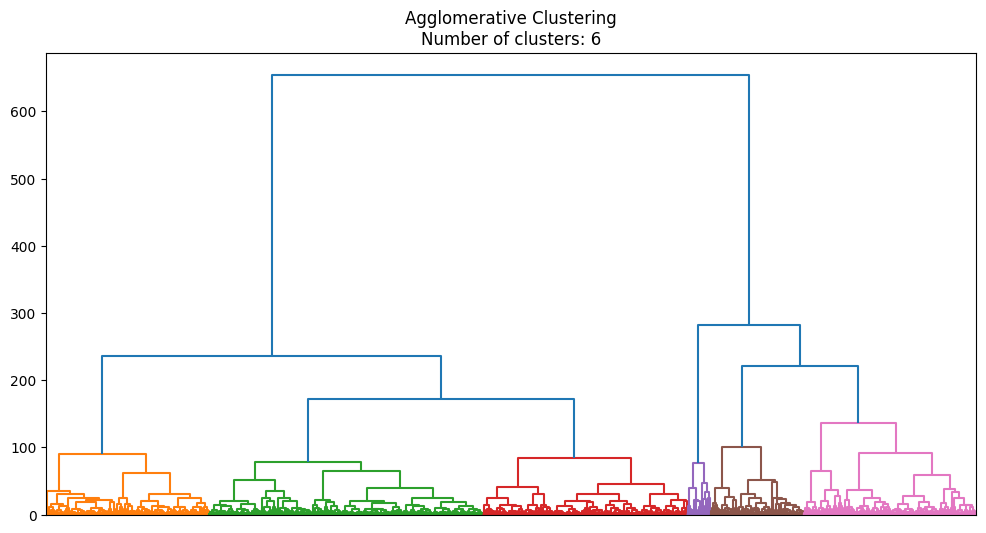

Number of clusters: 6
0.26559052
13038.89083322108
1.1061162619670668
0.0
[3, 2, 2, 2, 3]


In [ ]:
# normal clustering, using normalized one-hot and phases
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import davies_bouldin_score

data_ori = np.array(action_phase_components)
data = np.squeeze(data_ori) 
# combined_data = np.hstack((data, reshaped_labels))
scaler = StandardScaler()
standardized_data = scaler.fit_transform(data)

# Hierarchical clustering
Z = linkage(standardized_data, method='ward')

# Dynamic tree cut
max_d = 150 # Adjust based on your dendrogram and data
clusters = fcluster(Z, max_d, criterion='distance')
num_clusters = len(np.unique(clusters))

cluster_sizes = np.bincount(clusters)

for cluster_id, size in enumerate(cluster_sizes):
    print(f"Cluster {cluster_id}: {size} samples")

# Match the labels and action phases into each cluster
clustered_labels = {}
for cluster_id in np.unique(clusters):
    clustered_labels[cluster_id] = all_action_labels[clusters == cluster_id]
# Match the labels into each cluster
clustered_phases = {}
for cluster_id in np.unique(clusters):
    clustered_phases[cluster_id] = resampled_all_action_phases[clusters == cluster_id]

clustered_phases_ori = {}
for cluster_id in np.unique(clusters):
    clustered_phases_ori[cluster_id] = all_action_phases[clusters == cluster_id]

# Visualize
fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(Z, color_threshold=max_d, ax=ax)

plt.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
plt.title(f'Agglomerative Clustering\nNumber of clusters: {num_clusters}')
plt.show()

print(f"Number of clusters: {len(np.unique(clusters))}")

score_SS = silhouette_score(standardized_data, clusters)
print(score_SS)
score_CKI = calinski_harabasz_score(standardized_data, clusters)
print(score_CKI)
score_DBS = davies_bouldin_score(standardized_data, clusters)
print(score_DBS)

# Calculate purity score
n_clusters = len(np.unique(clusters))
# Convert one-hot encoded labels back to integer labels
decoded_labels = np.argmax(reshaped_labels, axis=1)
decoded_labels = np.argmax(reshaped_labels, axis=1)

dominant_labels = []
for cluster_id in range(n_clusters):
    # Extract labels of samples in this cluster
    cluster_labels = decoded_labels[clusters == cluster_id]
    
    if len(cluster_labels) == 0:  # Check if the cluster is empty
        continue

    # Find the label that occurs most frequently in this cluster
    dominant_label = np.bincount(cluster_labels).argmax()
    dominant_labels.append(dominant_label)

unique_dominant_labels = set(dominant_labels)
purity_score = sum([dominant_labels.count(label) == 1 for label in unique_dominant_labels]) / n_clusters
print(purity_score)
print(dominant_labels)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

all_possible_labels = ['I', 'D', 'H', 'L']
variables = ["$v$", "$a$", "$T$", "$\Delta v$"]
percentage_data = np.zeros((len(variables), len(all_possible_labels), len(clustered_labels)))
for cluster_idx, cluster_id in enumerate(clustered_labels.keys()):
    labels = clustered_labels[cluster_id]
    for var_idx, var in enumerate(variables):
        for label_idx, label in enumerate(all_possible_labels):
            var_label_count = np.sum((labels[:, var_idx] == label))
            total_count = len(labels)
            percentage = var_label_count / total_count
            percentage_data[var_idx, label_idx, cluster_idx] = percentage

sum_across_clusters = np.sum(percentage_data, axis=2, keepdims=True)
normalized_percentage_data = percentage_data / sum_across_clusters

# Save the metrics to a CSV file
metrics_df = pd.DataFrame(normalized_percentage_data.reshape(len(variables)*len(all_possible_labels), len(clustered_labels)),
                          index=[f"{var}-{label}" for var in variables for label in all_possible_labels],
                          columns=[f"Cluster {i+1}" for i in range(len(clustered_labels))])
metrics_df.to_csv('Agg_cluster_metrics.csv')

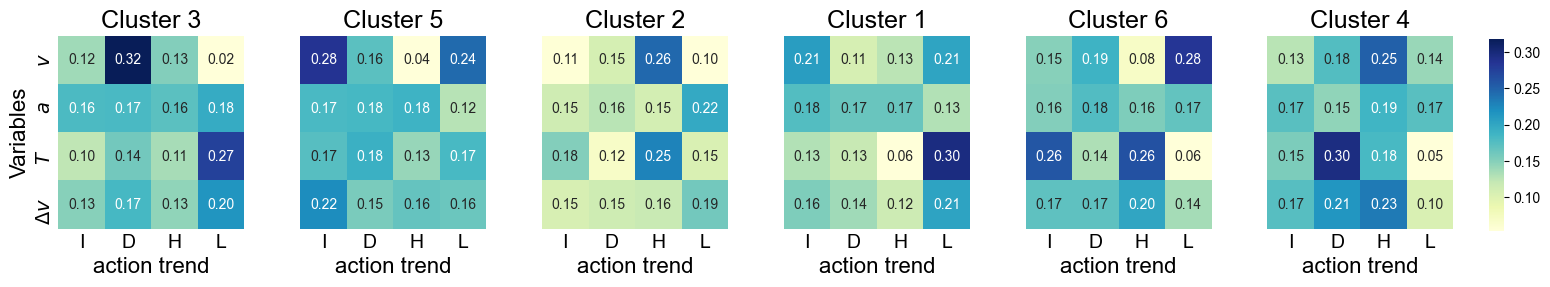

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

loaded_metrics_df = pd.read_csv('Agg_cluster_metrics.csv', index_col=0)

# Extracting the number of clusters from the loaded data
num_clusters = loaded_metrics_df.shape[1]

# Define the labels for the clusters
cluster_labels = [f'Cluster {cluster_idx + 1}' for cluster_idx in range(num_clusters)]
custom_order = ['Cluster 3', 'Cluster 5', 'Cluster 2', 'Cluster 1', 'Cluster 6', 'Cluster 4']

# Font settings
font_settings = {
    'title': {'fontsize': 18, 'fontweight': 'normal'},
    'label': {'fontsize': 16, 'fontweight': 'normal'},
    'tick': {'fontsize': 16, 'fontweight': 'normal', 'fontstyle': 'italic'}
}
tick_fontsize = 14  # You can adjust this value as needed

cluster_labels = [label for label in custom_order]
ordered_cluster_indices = [int(label.split(' ')[-1]) - 1 for label in custom_order]  # Convert cluster label to index
loaded_metrics_df = loaded_metrics_df.iloc[:, ordered_cluster_indices]

# Create subplots for each cluster in a single row
fig, axs = plt.subplots(1, num_clusters, figsize=(18, 2.5))
cbar_ax = fig.add_axes([0.92, 0.1, 0.008, 0.77])  # Position for the colorbar
max_value = np.nanmax(loaded_metrics_df.values)  # Maximum value for colorbar scaling

for cluster_idx, ax in enumerate(axs):
    cluster_label = cluster_labels[cluster_idx]
    
    # Extracting the percentage data for the current cluster
    percentage_matrix = loaded_metrics_df.iloc[:, cluster_idx].values.reshape(len(variables), len(all_possible_labels))
    
    # Create a heatmap for the cluster
    sns.heatmap(percentage_matrix, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=all_possible_labels, yticklabels=variables if cluster_idx == 0 else [], ax=ax, cbar=ax == axs[-1], cbar_ax=None if ax != axs[-1] else cbar_ax, vmax=max_value)
    ax.set_xlabel('action trend', **font_settings['label'])
    if cluster_idx == 0:
        ax.set_ylabel('Variables', **font_settings['label'])
    ax.set_title(cluster_label, **font_settings['title'])
    ax.tick_params(axis="x", length=0, labelsize=tick_fontsize)
    ax.tick_params(axis="y", length=0, labelsize=tick_fontsize)

# Adjust layout and spacing
plt.subplots_adjust(right=0.9, wspace=0.3)
plt.savefig('agg_cluster01.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()


X-means

In [17]:
## X-means
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Perform K-Means clustering
n_clusters = 6  # Replace with the optimal number of clusters you found
data_ori = np.array(action_phase_components)
data = np.squeeze(data_ori) 
standardized_data = scaler.fit_transform(data)
kmeans = KMeans(n_clusters=n_clusters, random_state=0)
clusters = kmeans.fit_predict(standardized_data)

# Calculate silhouette, Calinski-Harabasz, and Davies-Bouldin scores
score_SS = silhouette_score(standardized_data, clusters)
score_CKI = calinski_harabasz_score(standardized_data, clusters)
score_DBS = davies_bouldin_score(standardized_data, clusters)

print(f"Silhouette Score: {score_SS}")
print(f"Calinski-Harabasz Score: {score_CKI}")
print(f"Davies-Bouldin Score: {score_DBS}")

# Calculate cluster sizes
cluster_sizes = np.bincount(clusters)

for cluster_id, size in enumerate(cluster_sizes):
    print(f"Cluster {cluster_id}: {size} samples")

# Analyze clusters and extract labels
clustered_labels = {}
for cluster_id in np.unique(clusters):
    clustered_labels[cluster_id] = all_action_labels[clusters == cluster_id]

clustered_phases = {}
for cluster_id in np.unique(clusters):
    clustered_phases[cluster_id] = resampled_all_action_phases[clusters == cluster_id]

clustered_phases_ori = {}
for cluster_id in np.unique(clusters):
    clustered_phases_ori[cluster_id] = all_action_phases[clusters == cluster_id]


Silhouette Score: 0.3288113474845886
Calinski-Harabasz Score: 13766.95731254688
Davies-Bouldin Score: 1.1114193625883202
Cluster 0: 2481 samples
Cluster 1: 7363 samples
Cluster 2: 5600 samples
Cluster 3: 1411 samples
Cluster 4: 1508 samples
Cluster 5: 437 samples


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

all_possible_labels = ['I', 'D', 'H', 'L']
variables = ["$v$", "$a$", "$T$", "$\Delta v$"]
percentage_data = np.zeros((len(variables), len(all_possible_labels), len(clustered_labels)))
for cluster_idx, cluster_id in enumerate(clustered_labels.keys()):
    labels = clustered_labels[cluster_id]
    for var_idx, var in enumerate(variables):
        for label_idx, label in enumerate(all_possible_labels):
            var_label_count = np.sum((labels[:, var_idx] == label))
            total_count = len(labels)
            percentage = var_label_count / total_count
            percentage_data[var_idx, label_idx, cluster_idx] = percentage

sum_across_clusters = np.sum(percentage_data, axis=2, keepdims=True)
normalized_percentage_data = percentage_data / sum_across_clusters

# Save the metrics to a CSV file
metrics_df = pd.DataFrame(normalized_percentage_data.reshape(len(variables)*len(all_possible_labels), len(clustered_labels)),
                          index=[f"{var}-{label}" for var in variables for label in all_possible_labels],
                          columns=[f"Cluster {i+1}" for i in range(len(clustered_labels))])
metrics_df.to_csv('Xmeans_cluster_metrics.csv')


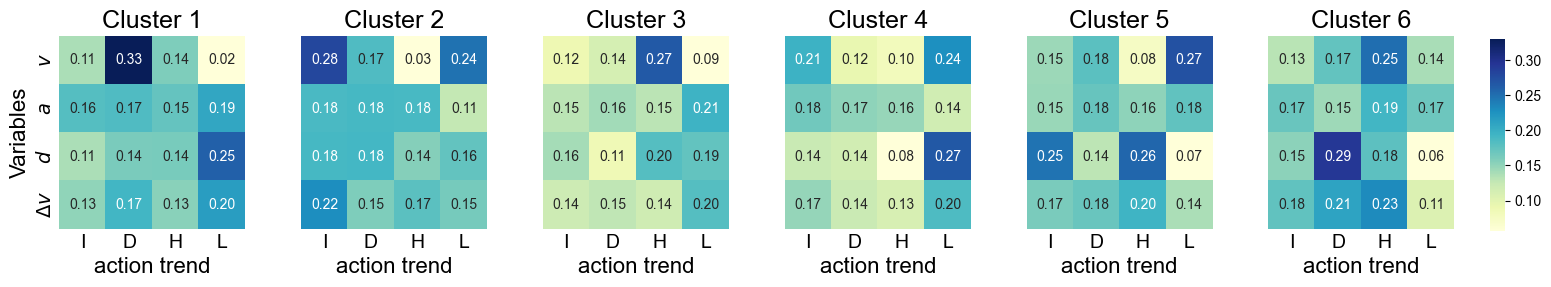

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

loaded_metrics_df = pd.read_csv('Xmeans_cluster_metrics.csv', index_col=0)

# Extracting the number of clusters from the loaded data
num_clusters = loaded_metrics_df.shape[1]

# Define the labels for the clusters
cluster_labels = [f'Cluster {cluster_idx + 1}' for cluster_idx in range(num_clusters)]

# Font settings
font_settings = {
    'title': {'fontsize': 18, 'fontweight': 'normal'},
    'label': {'fontsize': 16, 'fontweight': 'normal'},
    'tick': {'fontsize': 16, 'fontweight': 'normal', 'fontstyle': 'italic'}
}
tick_fontsize = 14  # You can adjust this value as needed

# Create subplots for each cluster in a single row
fig, axs = plt.subplots(1, num_clusters, figsize=(18, 2.5))
cbar_ax = fig.add_axes([0.92, 0.1, 0.008, 0.77])  # Position for the colorbar

max_value = np.nanmax(loaded_metrics_df.values)  # Maximum value for colorbar scaling

for cluster_idx, ax in enumerate(axs):
    cluster_label = cluster_labels[cluster_idx]
    
    # Extracting the percentage data for the current cluster
    percentage_matrix = loaded_metrics_df.iloc[:, cluster_idx].values.reshape(len(variables), len(all_possible_labels))
    
    # Create a heatmap for the cluster
    sns.heatmap(percentage_matrix, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=all_possible_labels, yticklabels=variables if cluster_idx == 0 else [], ax=ax, cbar=ax == axs[-1], cbar_ax=None if ax != axs[-1] else cbar_ax, vmax=max_value)
    ax.set_xlabel('action trend', **font_settings['label'])
    if cluster_idx == 0:
        ax.set_ylabel('Variables', **font_settings['label'])
    ax.set_title(cluster_label, **font_settings['title'])
    ax.tick_params(axis="x", length=0, labelsize=tick_fontsize)
    ax.tick_params(axis="y", length=0, labelsize=tick_fontsize)

# Adjust layout and spacing
plt.subplots_adjust(right=0.9, wspace=0.3)
plt.savefig('xmeans_cluster01.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()


Normalized data - KL

In [ ]:
# Calculate slopes of clusters
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

def compute_slopes(cluster, window_size=10):
    """
    Compute slopes for the given cluster.
    """
    lr = LinearRegression()
    
    # Create 4 lists to store the final slope indicators for each variable
    final_slopes = {
        'v': [],
        'a': [],
        'T': [],
        'dv': []
    }

    # For each action phase
    for i, action_phase in enumerate(cluster):
        # For each variable in the action phase (velocity, acceleration, etc.)
        for j, variable_curve in enumerate(action_phase):
            slopes = []

            # Calculate the slope for each window
            for k in range(window_size, len(variable_curve)):
                y = variable_curve[k-window_size:k].reshape(-1, 1)
                x = np.array(range(window_size)).reshape(-1, 1)
                lr.fit(x, y)
                slopes.append(lr.coef_[0][0])

            # The final slope indicator could be the mean of all slopes
            final_slope_indicator = np.mean(slopes)

            # Store the final slope indicator in the appropriate list
            if j == 0:
                final_slopes['v'].append(final_slope_indicator)
            elif j == 1:
                final_slopes['a'].append(final_slope_indicator)
            elif j == 2:
                final_slopes['T'].append(final_slope_indicator)
            elif j == 3:
                final_slopes['dv'].append(final_slope_indicator)

    return final_slopes

# Compute slopes for all clusters
all_slopes = {}
for cluster_id, cluster in clustered_phases_ori.items():
    all_slopes[cluster_id] = compute_slopes(cluster)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Initialize Min-Max Scaler for each variable
scalers = {var: MinMaxScaler() for var in variables}

# Concatenate data from all clusters for each variable
all_data_concatenated = {var: np.concatenate([all_slopes[cluster_id][var] for cluster_id in cluster_ids]) for var in variables}

# Fit the scaler on data from all clusters and transform
for var in variables:
    scalers[var].fit(all_data_concatenated[var].reshape(-1, 1))

# Normalize the data
normalized_slopes = {cluster_id: {var: scalers[var].transform(np.array(all_slopes[cluster_id][var]).reshape(-1, 1)).flatten() for var in variables} for cluster_id in cluster_ids}

In [ ]:
# Function to calculate KL Divergence
def kl_divergence(p, q):
    return np.sum(np.where(p != 0, p * np.log(p / q), 0))

cluster_ids = list(all_slopes.keys())
num_clusters = len(cluster_ids)
num_bins = 30

# Initialize KL divergence matrices
kl_matrices = {var: np.zeros((num_clusters, num_clusters)) for var in variables}

# Calculate KL divergence for each variable
for var in variables:
    # Define bins for this variable
    all_data = np.concatenate([normalized_slopes[cluster_id][var] for cluster_id in cluster_ids])
    min_val, max_val = all_data.min(), all_data.max()
    bins = np.linspace(min_val, max_val, num_bins + 1)

    # Compute histograms for each cluster
    histograms = {}
    for cluster_id in cluster_ids:
        histogram, _ = np.histogram(normalized_slopes[cluster_id][var], bins, density=True)
        histograms[cluster_id] = histogram

    # Calculate KL divergence
    for i, id1 in enumerate(cluster_ids):
        for j, id2 in enumerate(cluster_ids):
            if id1 != id2:
                hist1 = np.clip(histograms[id1], a_min=1e-10, a_max=None)
                hist2 = np.clip(histograms[id2], a_min=1e-10, a_max=None)
                kl_matrices[var][i, j] = kl_divergence(hist1, hist2)


In [ ]:
# Plotting the heatmaps
fig, axs = plt.subplots(1, len(variables), figsize=(18, 3.9))
cbar_ax = fig.add_axes([0.92, 0.112, 0.01, 0.76])  # Position for the colorbar

font_settings = {
    'title': {'fontsize': 18, 'fontweight': 'normal'},
    'label': {'fontsize': 16, 'fontweight': 'normal'},
    'tick': {'fontsize': 16, 'fontweight': 'normal'}
}
tick_fontsize = 18  # You can adjust this value as needed
legend_fontsize = 16  # Font size for the legend

# Determine the global maximum KL divergence for a consistent color scale
max_kl = max(matrix.max() for matrix in kl_matrices.values())
for ax, (var, matrix) in zip(axs, kl_matrices.items()):
    sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap='coolwarm', vmax=max_kl,
                cbar=ax == axs[-1], cbar_ax=None if ax != axs[-1] else cbar_ax)
    
    # Update title with LaTeX symbol
    title_var = f"\\Delta v" if var == "dv" else var
    ax.set_title(f'KL Divergence - ${title_var}$', **font_settings['title'])
    
    ax.set_xlabel('Cluster ID', **font_settings['label'])
    ax.set_ylabel('Cluster ID', **font_settings['label'])
    ax.set_xticklabels(cluster_ids, rotation=0, **font_settings['tick'])
    ax.set_yticklabels(cluster_ids, rotation=0, **font_settings['tick'])
    ax.tick_params(axis='both', which='major', labelsize=tick_fontsize)

plt.subplots_adjust(right=0.9, wspace=0.3)

plt.savefig('KL_check.pdf', format='png', dpi=300, bbox_inches='tight')
plt.show()